In [4]:
#Regression
#Today we will go deep in to regression

In [6]:
#pip install xlrd

Note: you may need to restart the kernel to use updated packages.


In [8]:
import pandas as pd

In [12]:
df=pd.read_excel("cars.xls")

In [14]:
#EDA Explotary Data Analysis

In [16]:
df.head()

,Price,Mileage,Make,Model,Trim,Type,Cylinder,Liter,Doors,Cruise,Sound,Leather
0,17314.103129,8221,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,1,1
1,17542.036083,9135,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,1,0
2,16218.847862,13196,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,1,0
3,16336.913140,16342,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,0,0
4,16339.170324,19832,Buick,Century,Sedan 4D,Sedan,6,3.1,4,1,0,1


In [18]:
df.shape

(804, 12)

In [20]:
df.sample()

,Price,Mileage,Make,Model,Trim,Type,Cylinder,Liter,Doors,Cruise,Sound,Leather
465,20676.165511,18021,Chevrolet,Monte Carlo,LT Coupe 2D,Coupe,6,3.8,2,1,0,1


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 804 entries, 0 to 803
Data columns (total 12 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Price     804 non-null    float64
 1   Mileage   804 non-null    int64  
 2   Make      804 non-null    object 
 3   Model     804 non-null    object 
 4   Trim      804 non-null    object 
 5   Type      804 non-null    object 
 6   Cylinder  804 non-null    int64  
 7   Liter     804 non-null    float64
 8   Doors     804 non-null    int64  
 9   Cruise    804 non-null    int64  
 10  Sound     804 non-null    int64  
 11  Leather   804 non-null    int64  
dtypes: float64(2), int64(6), object(4)
memory usage: 75.5+ KB


In [24]:
#Statistic

In [26]:
df.describe()

,Price,Mileage,Cylinder,Liter,Doors,Cruise,Sound,Leather
count,804.000000,804.000000,804.000000,804.000000,804.000000,804.000000,804.000000,804.000000
mean,21343.143767,19831.934080,5.268657,3.037313,3.527363,0.752488,0.679104,0.723881
std,9884.852801,8196.319707,1.387531,1.105562,0.850169,0.431836,0.467111,0.447355
min,8638.930895,266.000000,4.000000,1.600000,2.000000,0.000000,0.000000,0.000000
25%,14273.073870,14623.500000,4.000000,2.200000,4.000000,1.000000,0.000000,0.000000
50%,18024.995019,20913.500000,6.000000,2.800000,4.000000,1.000000,1.000000,1.000000
75%,26717.316636,25213.000000,6.000000,3.800000,4.000000,1.000000,1.000000,1.000000
max,70755.466717,50387.000000,8.000000,6.000000,4.000000,1.000000,1.000000,1.000000


In [30]:
df.corr(numeric_only=True)

,Price,Mileage,Cylinder,Liter,Doors,Cruise,Sound,Leather
Price,1.000000,-0.143051,0.569086,0.558146,-0.138750,0.430851,-0.124348,0.157197
Mileage,-0.143051,1.000000,-0.029461,-0.018641,-0.016944,0.025037,-0.026146,0.001005
Cylinder,0.569086,-0.029461,1.000000,0.957897,0.002206,0.354285,-0.089704,0.075520
Liter,0.558146,-0.018641,0.957897,1.000000,-0.079259,0.377509,-0.065527,0.087332
Doors,-0.138750,-0.016944,0.002206,-0.079259,1.000000,-0.047674,-0.062530,-0.061969
Cruise,0.430851,0.025037,0.354285,0.377509,-0.047674,1.000000,-0.091730,-0.070573
Sound,-0.124348,-0.026146,-0.089704,-0.065527,-0.062530,-0.091730,1.000000,0.165444
Leather,0.157197,0.001005,0.075520,0.087332,-0.061969,-0.070573,0.165444,1.000000


In [32]:
import seaborn as sns

<Axes: >

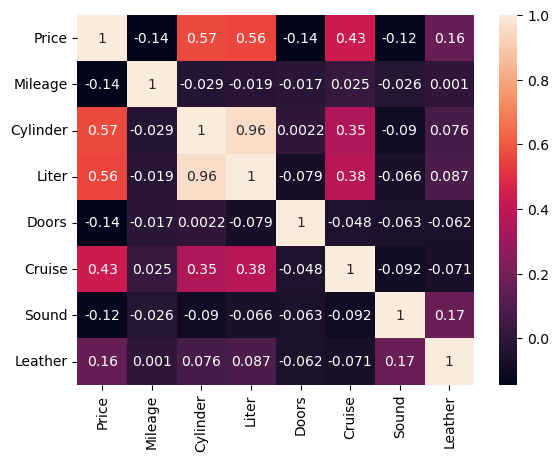

In [36]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [38]:
#Formula for outliers +-3* standart dev.

In [42]:
df["Price"].mean(),df["Price"].median(),df["Price"].min(),df["Price"].max(),df["Price"].std(),

(21343.143767325837,
 18024.995019071903,
 8638.930895260657,
 70755.46671654288,
 9884.852800898007)

In [44]:
df.tail()

,Price,Mileage,Make,Model,Trim,Type,Cylinder,Liter,Doors,Cruise,Sound,Leather
799,16507.070267,16229,Saturn,L Series,L300 Sedan 4D,Sedan,6,3.0,4,1,0,0
800,16175.957604,19095,Saturn,L Series,L300 Sedan 4D,Sedan,6,3.0,4,1,1,0
801,15731.132897,20484,Saturn,L Series,L300 Sedan 4D,Sedan,6,3.0,4,1,1,0
802,15118.893228,25979,Saturn,L Series,L300 Sedan 4D,Sedan,6,3.0,4,1,1,0
803,13585.636802,35662,Saturn,L Series,L300 Sedan 4D,Sedan,6,3.0,4,1,0,0


In [46]:
df.isnull().sum()# which column has empty value

Price       0
Mileage     0
Make        0
Model       0
Trim        0
Type        0
Cylinder    0
Liter       0
Doors       0
Cruise      0
Sound       0
Leather     0
dtype: int64

In [50]:
df["Make"].unique()

array(['Buick', 'Cadillac', 'Chevrolet', 'Pontiac', 'SAAB', 'Saturn'],
      dtype=object)

In [52]:
df["Make"].nunique()

6

In [56]:
df["Make"].value_counts()#How many of which brand of car are there?

Make
Chevrolet    320
Pontiac      150
SAAB         114
Buick         80
Cadillac      80
Saturn        60
Name: count, dtype: int64

In [58]:
df["Make"].value_counts(normalize=True)

Make
Chevrolet    0.398010
Pontiac      0.186567
SAAB         0.141791
Buick        0.099502
Cadillac     0.099502
Saturn       0.074627
Name: proportion, dtype: float64

[Text(0, 0, '80'),
 Text(0, 0, '80'),
 Text(0, 0, '320'),
 Text(0, 0, '150'),
 Text(0, 0, '114'),
 Text(0, 0, '60')]

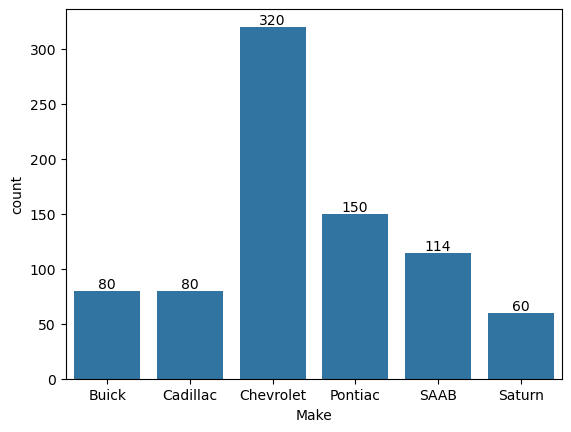

In [66]:
ax=sns.countplot(x=df["Make"])
ax.bar_label(ax.containers[0])

<Axes: xlabel='Cylinder', ylabel='count'>

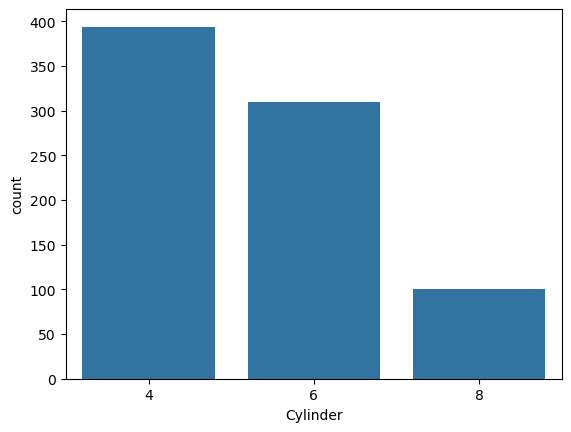

In [68]:
sns.countplot(x=df["Cylinder"])

<Axes: xlabel='count', ylabel='Doors'>

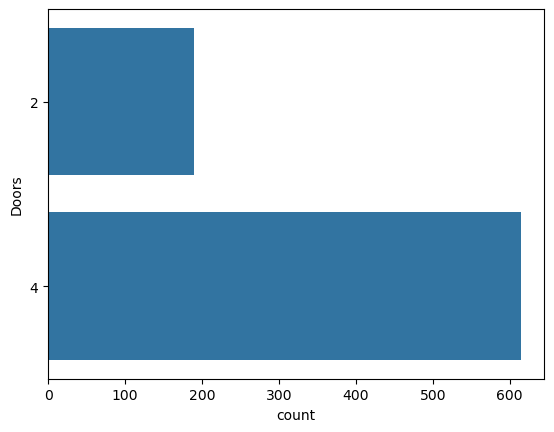

In [72]:
sns.countplot(y=df["Doors"])

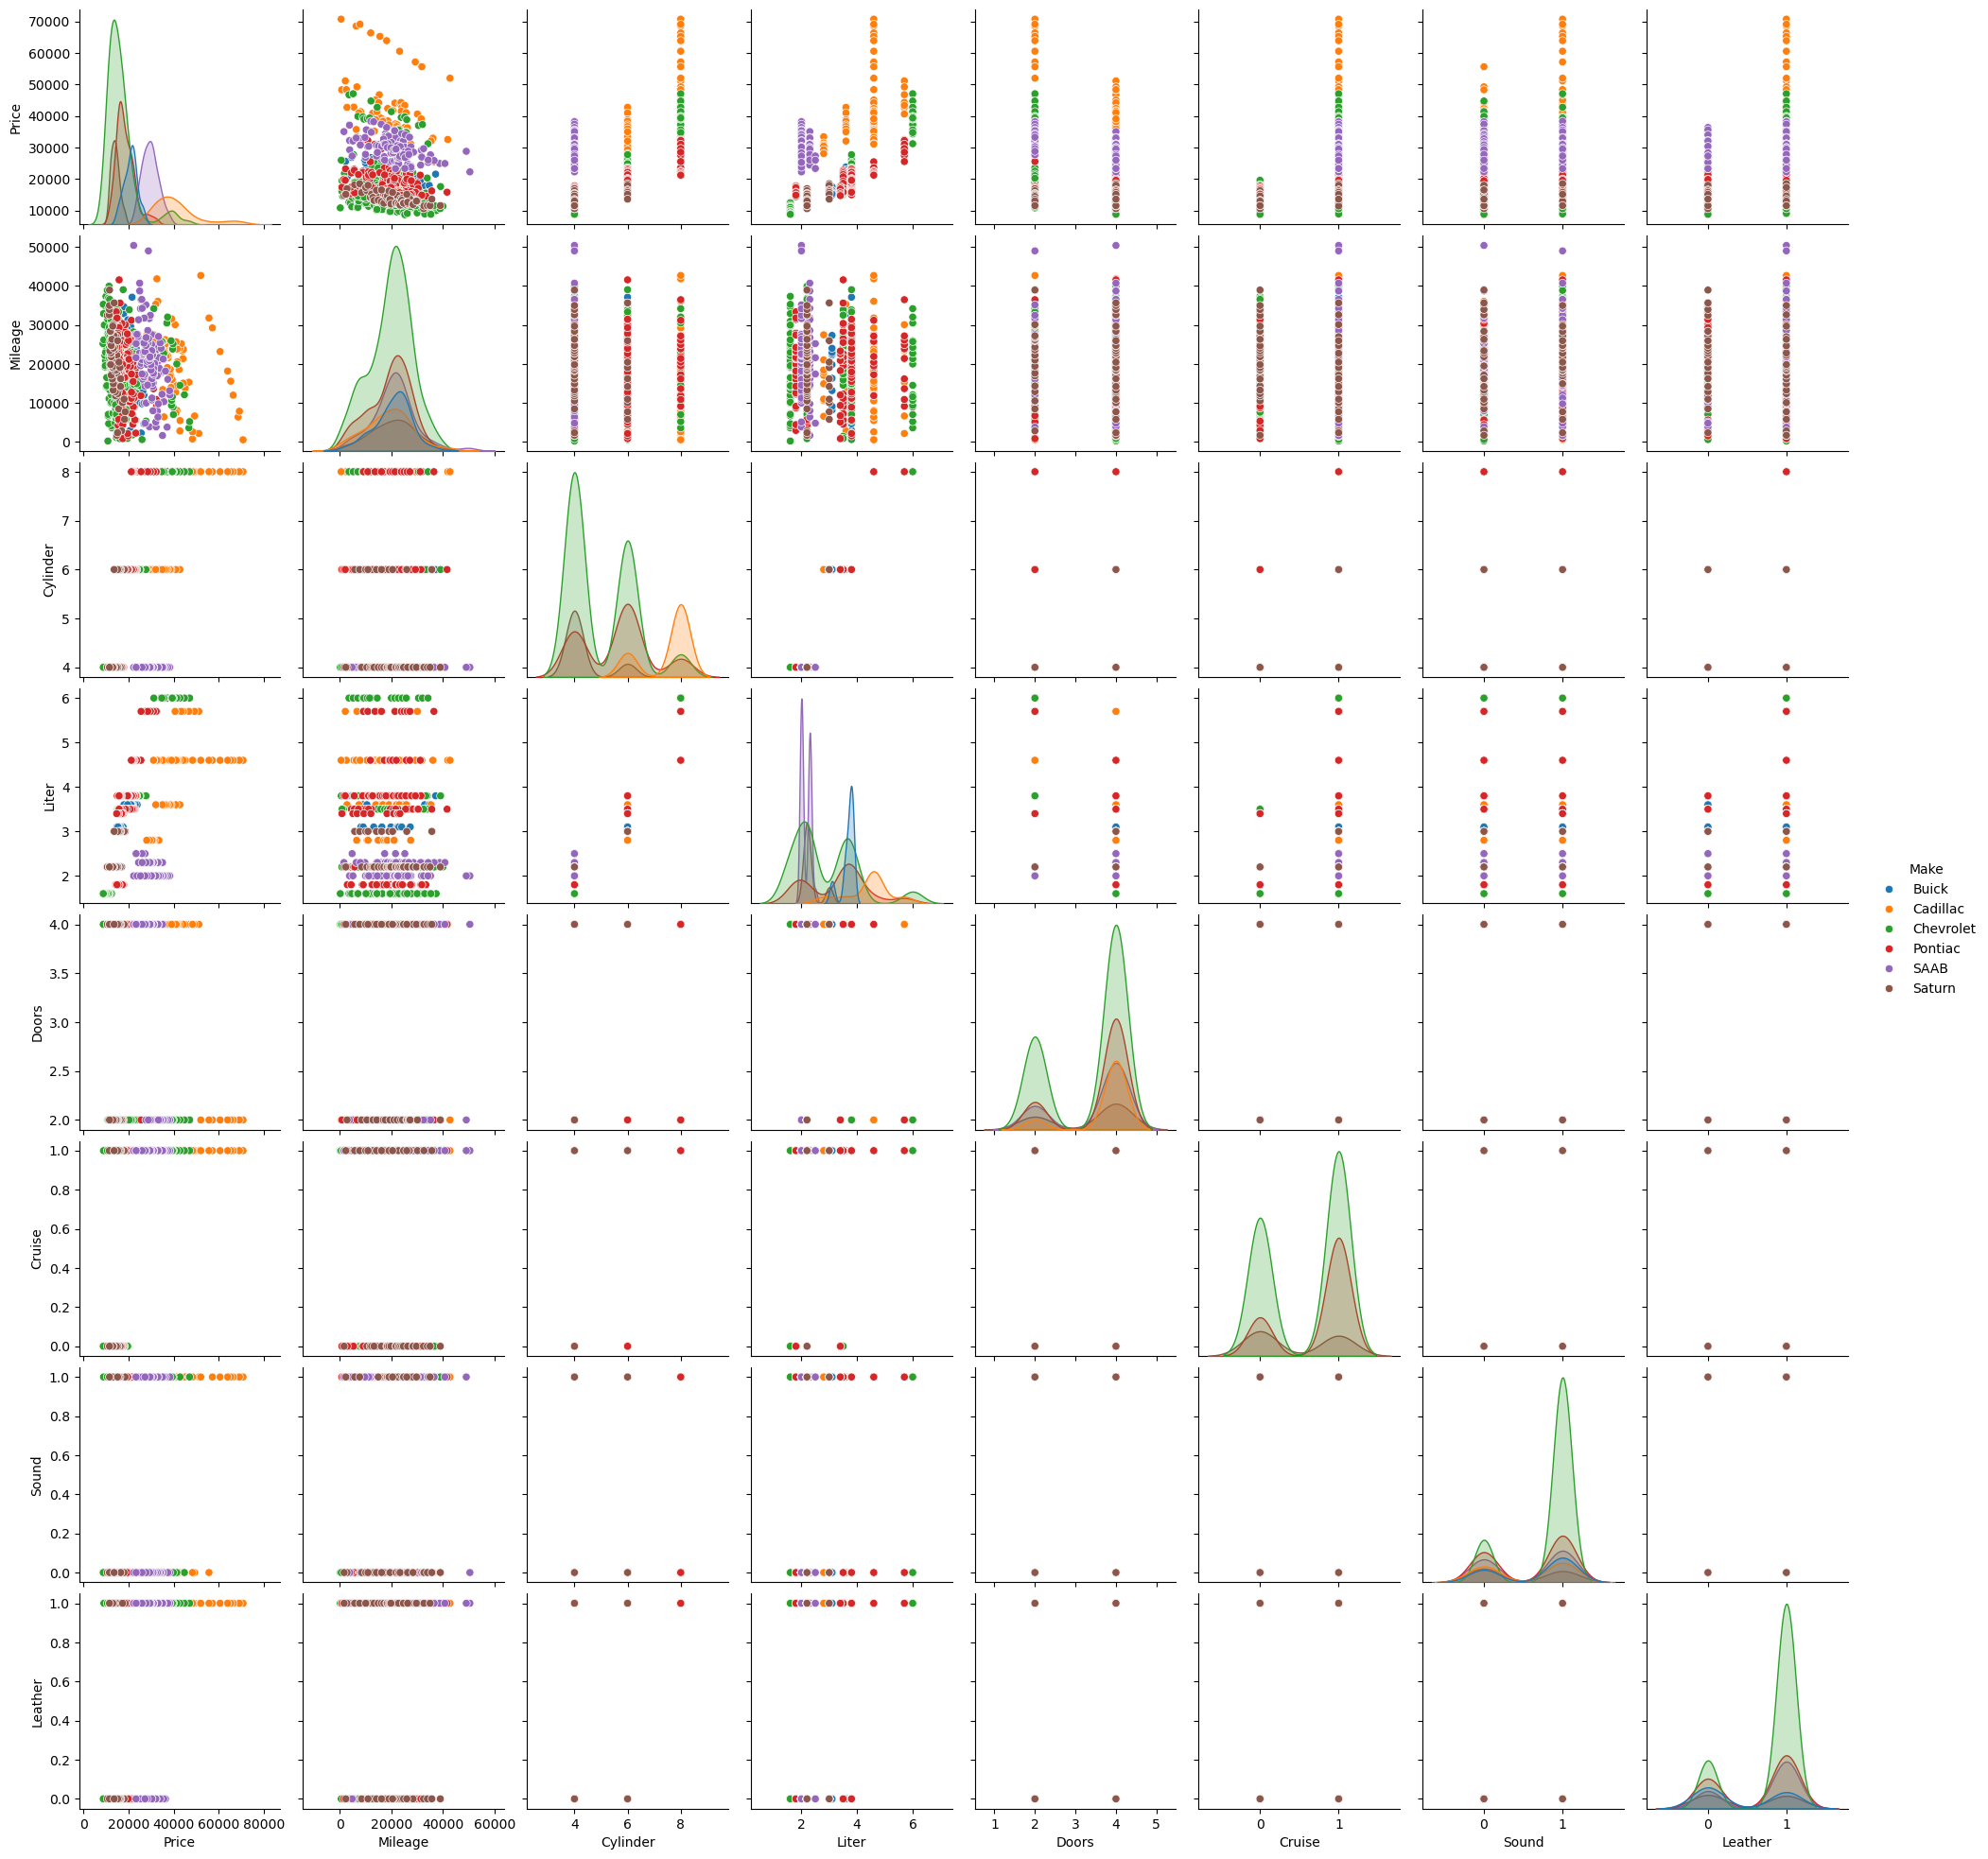

In [76]:
sns.pairplot(df, hue="Make")

<Axes: xlabel='Price', ylabel='Mileage'>

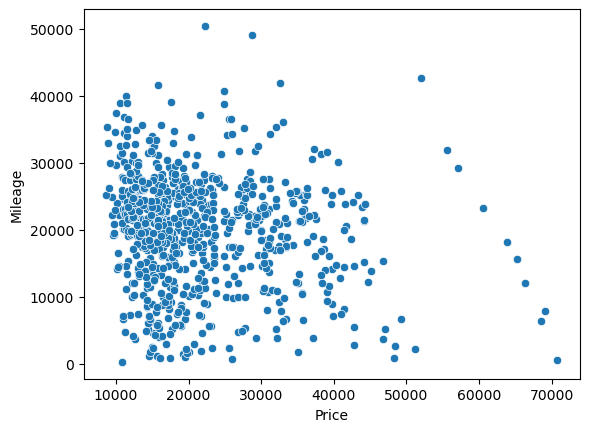

In [78]:
sns.scatterplot(x="Price", y="Mileage",data=df)

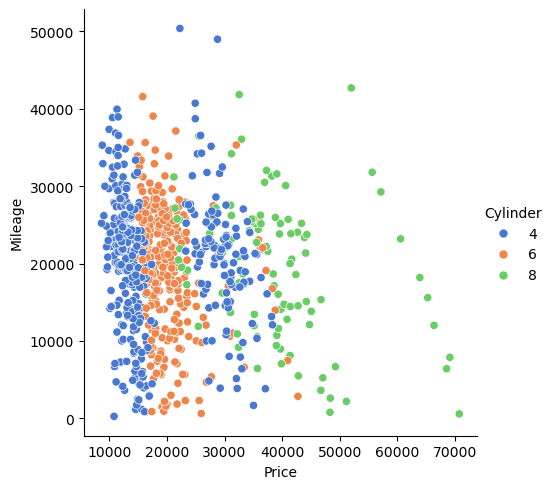

In [82]:
sns.relplot(x="Price", y="Mileage",hue="Cylinder",palette="muted",data=df)

In [84]:
"""H0= no connection betwwen price and mileage
Ha= there is a connection
if p<0.05 Ha is true else H0 is true
"""

'H0= no connection betwwen price and milage\nHa= there is a connection\nif p<0.05 Ha is true else H0 is true\n'

In [86]:
from scipy.stats import ttest_ind

In [90]:
_,p=ttest_ind(df["Price"],df["Mileage"])
p

0.0008662338227446262

In [92]:
# so p=0.0008662338227446262 <0.05, we accept Ha

<Axes: xlabel='Price', ylabel='Count'>

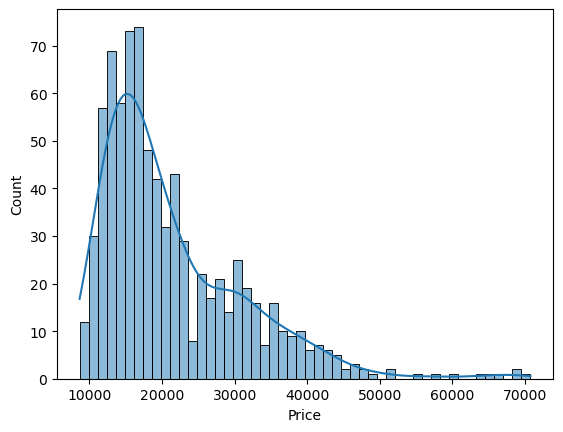

In [100]:
sns.histplot(x=df["Price"], kde=True,bins=50)

<Axes: xlabel='Price', ylabel='Density'>

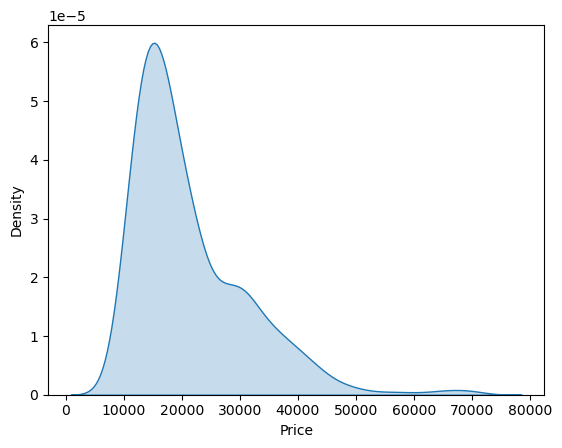

In [102]:
sns.kdeplot(x=df["Price"],fill=True)

<Axes: >

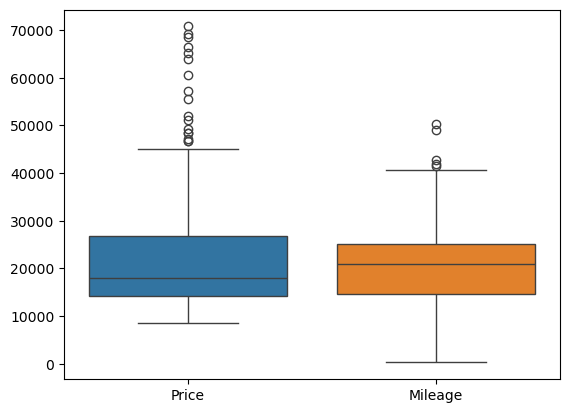

In [110]:
sns.boxplot([df["Price"],df["Mileage"]])

<Axes: xlabel='Make', ylabel='Price'>

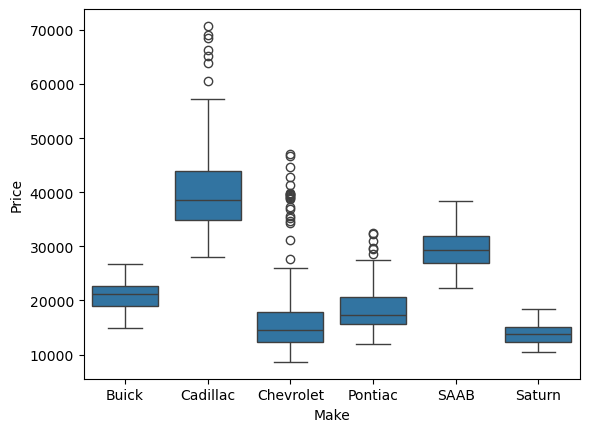

In [114]:
sns.boxplot(x="Make",y="Price", data=df)

<Axes: xlabel='Make', ylabel='Price'>

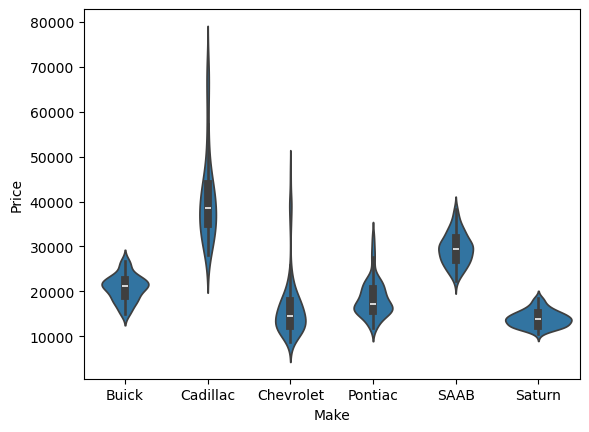

In [116]:
sns.violinplot(x="Make",y="Price", data=df)

In [118]:
import plotly.express as px

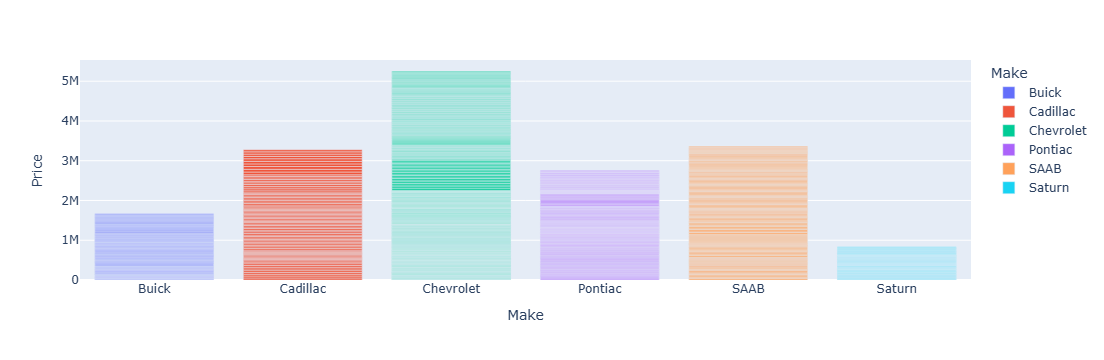

In [120]:
px.bar(df, x="Make",y="Price",color="Make")

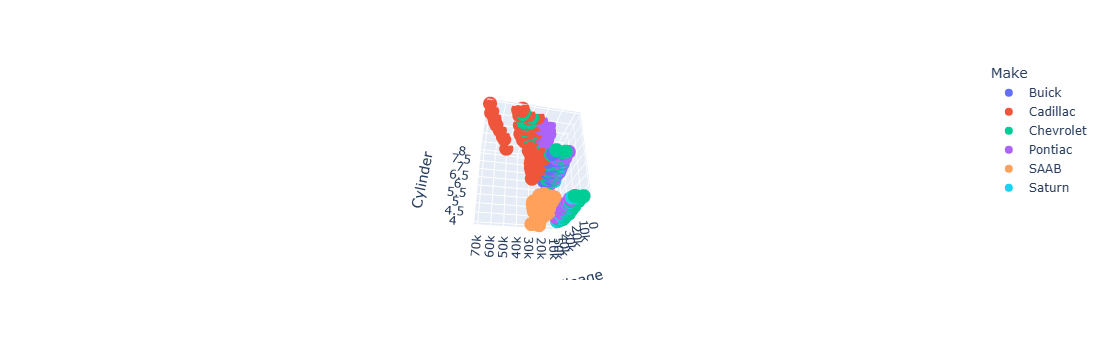

In [122]:
px.scatter_3d(df, x="Mileage",y="Price",color="Make",z="Cylinder")

In [124]:
""" datascience, MLOps """


' datascience, MLOps '

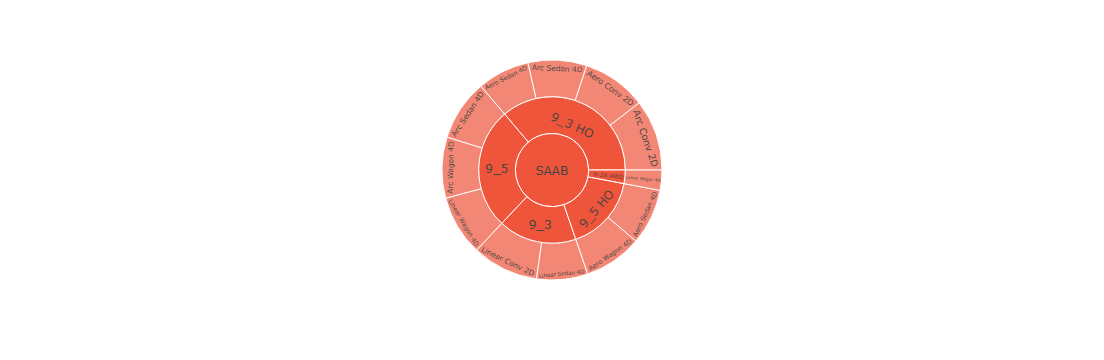

In [128]:
px.sunburst(df, path=["Make","Model","Trim"], values="Price")

In [130]:
#Feature Engineering

In [132]:
df.corr(numeric_only=True)

,Price,Mileage,Cylinder,Liter,Doors,Cruise,Sound,Leather
Price,1.000000,-0.143051,0.569086,0.558146,-0.138750,0.430851,-0.124348,0.157197
Mileage,-0.143051,1.000000,-0.029461,-0.018641,-0.016944,0.025037,-0.026146,0.001005
Cylinder,0.569086,-0.029461,1.000000,0.957897,0.002206,0.354285,-0.089704,0.075520
Liter,0.558146,-0.018641,0.957897,1.000000,-0.079259,0.377509,-0.065527,0.087332
Doors,-0.138750,-0.016944,0.002206,-0.079259,1.000000,-0.047674,-0.062530,-0.061969
Cruise,0.430851,0.025037,0.354285,0.377509,-0.047674,1.000000,-0.091730,-0.070573
Sound,-0.124348,-0.026146,-0.089704,-0.065527,-0.062530,-0.091730,1.000000,0.165444
Leather,0.157197,0.001005,0.075520,0.087332,-0.061969,-0.070573,0.165444,1.000000


In [134]:
abs(df.corr(numeric_only=True)["Price"].sort_values(ascending=False))

Price       1.000000
Cylinder    0.569086
Liter       0.558146
Cruise      0.430851
Leather     0.157197
Sound       0.124348
Doors       0.138750
Mileage     0.143051
Name: Price, dtype: float64

In [138]:
x=df[["Cylinder","Liter","Cruise","Mileage"]]
y=df[["Price"]]

In [142]:
from sklearn.model_selection import train_test_split

In [144]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.20,random_state=42)

In [150]:
x_train.shape, x_test.shape

((643, 4), (161, 4))

In [152]:
from sklearn.linear_model import LinearRegression

In [154]:
lr=LinearRegression()

In [156]:
model=lr.fit(x_train,y_train)# Machine Learning

In [158]:
pred=model.predict(x_test)

In [160]:
from sklearn.metrics import r2_score, mean_squared_error

In [174]:
mean_squared_error(y_test, pred)**0.5

7413.255792158785

In [164]:
r2_score(y_test, pred)

0.30711149069980326

In [176]:
#Since we cannot you use brand names our prediction came out too low
#now we will be doing Label Encoding using sparse matrixes

In [170]:
x=df[["Cylinder","Liter","Cruise","Mileage","Make","Trim"]]
y=df[["Price"]]

In [172]:
x.head()

,Cylinder,Liter,Cruise,Mileage,Make,Trim
0,6,3.1,1,8221,Buick,Sedan 4D
1,6,3.1,1,9135,Buick,Sedan 4D
2,6,3.1,1,13196,Buick,Sedan 4D
3,6,3.1,1,16342,Buick,Sedan 4D
4,6,3.1,1,19832,Buick,Sedan 4D


In [178]:
x=pd.get_dummies(x,drop_first=True)

In [180]:
x.head()

,Cylinder,Liter,Cruise,Mileage,Make_Cadillac,Make_Chevrolet,Make_Pontiac,Make_SAAB,Make_Saturn,Trim_Aero Conv 2D,...,Trim_Quad Coupe 2D,Trim_SE Sedan 4D,Trim_SLE Sedan 4D,Trim_SS Coupe 2D,Trim_SS Sedan 4D,Trim_SVM Hatchback 4D,Trim_SVM Sedan 4D,Trim_Sedan 4D,Trim_Special Ed Ultra 4D,Trim_Sportwagon 4D
0,6,3.1,1,8221,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,6,3.1,1,9135,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,6,3.1,1,13196,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,6,3.1,1,16342,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
4,6,3.1,1,19832,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False


In [182]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.20,random_state=42)

In [184]:
model=lr.fit(x_train,y_train)# Machine Learning

In [186]:
pred=model.predict(x_test)

In [192]:
mean_squared_error(y_test, pred)**0.5# 1500 dolar error prediction

1523.6314728604007

In [190]:
r2_score(y_test, pred)

0.97073117701105

In [194]:
#pd.set_option('display.max_columns', None)# To see all columns

In [196]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet

In [200]:
R=Ridge()
L=Lasso()
E=ElasticNet()

In [202]:
Rmodel=R.fit(x_train,y_train)

In [204]:
pred2=Rmodel.predict(x_test)

In [206]:
mean_squared_error(y_test, pred2)**0.5

1575.6786242840067

In [208]:
r2_score(y_test, pred2)

0.9686973810318731

In [210]:
Lmodel=L.fit(x_train,y_train)
pred3=Lmodel.predict(x_test)

In [212]:
mean_squared_error(y_test, pred3)**0.5

1527.0417304803855

In [214]:
r2_score(y_test, pred3)

0.9706000089003125

In [220]:
Emodel=E.fit(x_train,y_train)
pred4=Emodel.predict(x_test)

In [222]:
mean_squared_error(y_test, pred4)**0.5

5916.1230445137135

In [224]:
r2_score(y_test, pred4)

0.5587143714698315

In [226]:
# Coefficents

In [228]:
lr.coef_

array([[-2.60219053e+03,  7.38331957e+03, -1.05024563e+02,
        -1.98809431e-01,  1.55364461e+04, -2.81688090e+03,
        -3.59594608e+03,  6.85100028e+03, -2.29878609e+03,
         3.90588224e+03, -2.64773527e+03, -1.26995361e+03,
         7.05993990e+03, -2.22310734e+02,  1.38127365e+02,
        -8.04390904e+03, -6.79607391e+03, -6.85437716e+03,
         3.54018314e+03, -5.72790226e+03, -1.11979437e+04,
        -8.32030557e+03, -7.59431897e+03, -8.10925499e+03,
        -6.53924263e+03, -3.82628105e+02, -5.76220228e+03,
        -3.63992297e+03,  1.67584142e+04, -5.32327214e+03,
        -7.83067529e+03, -4.64523486e+03, -7.53303979e+03,
        -6.65186020e+03, -7.63546793e+03, -6.87040602e+03,
        -6.33606759e+03, -3.92489639e+03, -7.03882417e+03,
        -6.17480932e+03, -8.14421976e+03,  4.52867027e+03,
        -2.53728086e+03, -2.10433902e+03, -7.88530569e+03,
        -6.07227049e+03, -6.65263910e+03, -5.53516395e+03,
        -4.78023915e+03, -3.13661125e+03, -6.92039280e+0

In [232]:
feature_importance=pd.DataFrame({"Feature":x_train.columns,"Coefs":lr.coef_[0]})

In [236]:
feature_importance=feature_importance.sort_values(by="Coefs", ascending=False)

In [238]:
feature_importance

,Feature,Coefs
28,Trim_Hardtop Conv 2D,16758.414214
4,Make_Cadillac,15536.446130
1,Liter,7383.319566
12,Trim_Arc Conv 2D,7059.939896
7,Make_SAAB,6851.000276
41,Trim_Linear Conv 2D,4528.670272
9,Trim_Aero Conv 2D,3905.882237
18,Trim_Conv 2D,3540.183140
14,Trim_Arc Wagon 4D,138.127365
3,Mileage,-0.198809


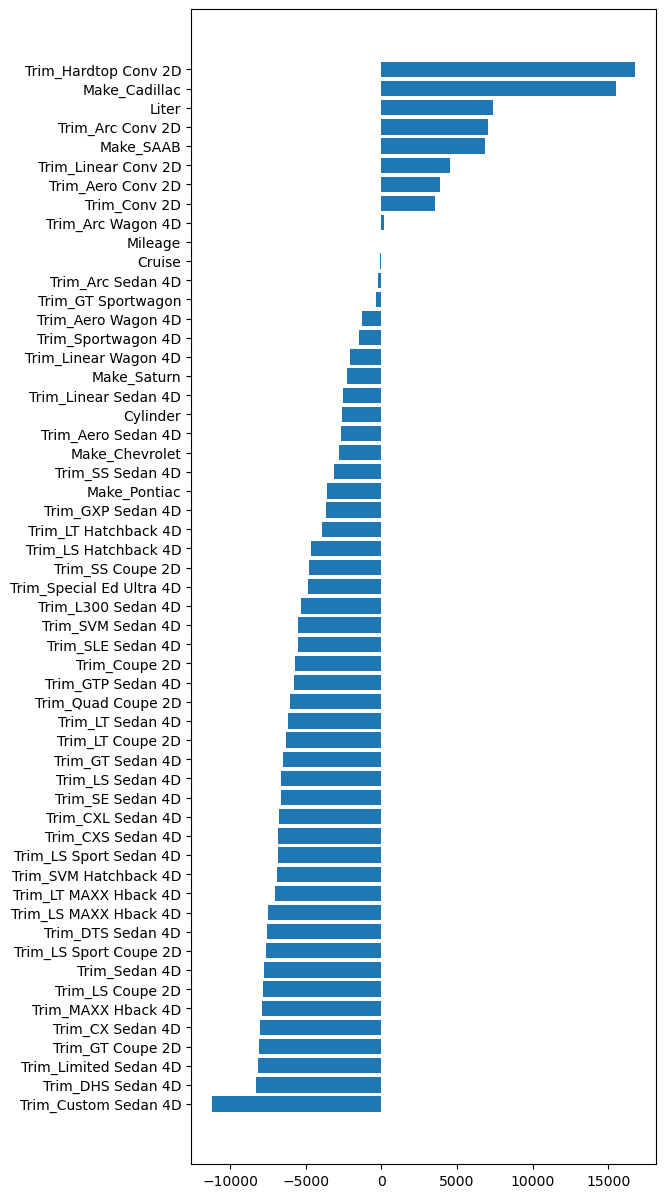

In [252]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,15))
plt.barh(feature_importance["Feature"],feature_importance["Coefs"])
plt.gca().invert_yaxis()

In [254]:
"""
What you need to know for the success rate in regression:
1-R2_score>0.85
2-Low RMS
3- Residuals should have follow normal distrubution

"""

'\nWhat you need to know for the success rate in regression:\n1-R2_score>0.85\n2-Low RMS\n3- Residuals should have follow normal distrubution\n\n'

In [258]:
residuals=y_test-pred
residuals


,Price
192,559.667912
717,1027.528386
168,1144.233441
522,2909.433116
536,494.086073
...,...
658,-812.069688
356,4025.396437
525,2361.161783
748,-961.806180


<Axes: ylabel='Count'>

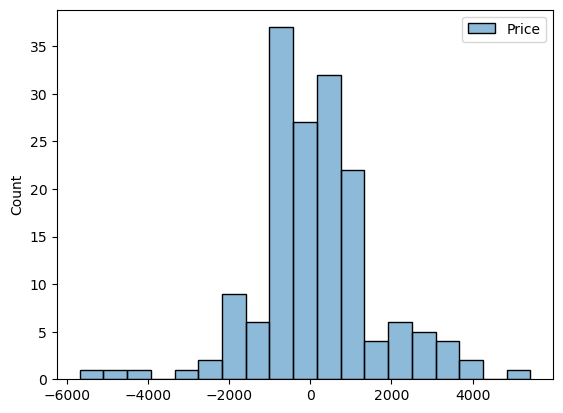

In [262]:
sns.histplot(residuals)

<Axes: xlabel='Price', ylabel='Density'>

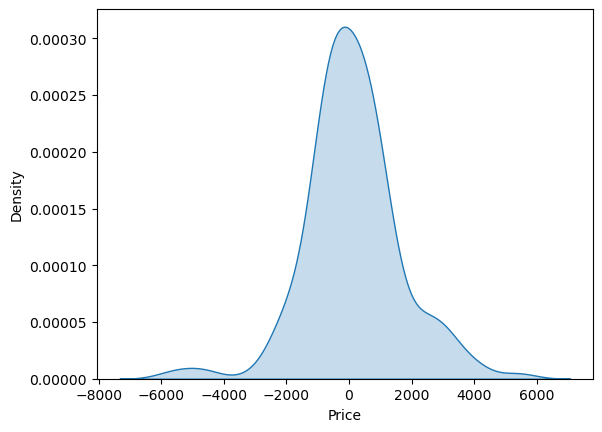

In [268]:
sns.kdeplot(x=residuals["Price"],fill=True)

In [270]:
from sklearn.tree import DecisionTreeRegressor

In [272]:
dt=DecisionTreeRegressor()

In [280]:
Dmodel=dt.fit(x_train,y_train)
pred5=dt.predict(x_test)


In [282]:
mean_squared_error(y_test,pred5)**0.5

1836.39311558692

In [284]:
r2_score(y_test, pred5)

0.9574816208893397

In [286]:
from sklearn.ensemble import ExtraTreesRegressor

In [288]:
et=ExtraTreesRegressor()

In [290]:
etmodel=et.fit(x_train,y_train)
pred6=et.predict(x_test)

C:\Users\omerf\anaconda3\Lib\site-packages\sklearn\base.py:1473: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().



In [294]:
mean_squared_error(y_test,pred6)**0.5

915.9411825575199

In [296]:
r2_score(y_test, pred6)

0.9894225602455232